<a href="https://colab.research.google.com/github/dritireddy/Consumer-Product-Preference-Analysis/blob/main/Consumer_Product_Preference_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import libraries and load the dataset**

In [18]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")


Libraries imported successfully!


**Upload and load CSV in Colab**

In [2]:

from google.colab import files

uploaded = files.upload()


Saving Product_Preference_Analysis.csv to Product_Preference_Analysis.csv


In [4]:

df = pd.read_csv("Product_Preference_Analysis.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


**Inspect the dataset**

In [19]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000



Missing values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Duplicate rows: 0


**Q1 — Data cleaning and preprocessing- [CO3, BL3]**

In [20]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert Date into datetime format
df["Date"] = pd.to_datetime(
    df["Date"], dayfirst=True, errors="coerce"
)

# Fill missing numerical values with the median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with "Unknown"
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("Unknown")

# Fill any missing dates using the most frequent date
if df["Date"].isnull().any() and df["Date"].notna().any():
    df["Date"] = df["Date"].fillna(df["Date"].mode()[0])

print("Dataset shape after cleaning:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape after cleaning: (1000, 17)
Total missing values: 0
Duplicate rows: 0


**Q2 — NumPy analysis of sales by product line [CO1, BL3]**

In [21]:
product_lines = df["Product line"].unique()

for product in product_lines:
    sales = df.loc[
        df["Product line"] == product, "Sales"
    ].to_numpy()

    print("\nProduct line:", product)
    print("Average sales:", np.mean(sales).round(2))
    print("Minimum sales:", np.min(sales).round(2))
    print("Maximum sales:", np.max(sales).round(2))


Product line: Health and beauty
Average sales: 323.64
Minimum sales: 18.64
Maximum sales: 950.25

Product line: Electronic accessories
Average sales: 319.63
Minimum sales: 26.72
Maximum sales: 942.45

Product line: Home and lifestyle
Average sales: 336.64
Minimum sales: 14.68
Maximum sales: 1023.75

Product line: Sports and travel
Average sales: 332.07
Minimum sales: 10.68
Maximum sales: 1002.12

Product line: Food and beverages
Average sales: 322.67
Minimum sales: 22.66
Maximum sales: 1034.46

Product line: Fashion accessories
Average sales: 305.09
Minimum sales: 12.69
Maximum sales: 1042.65


**Q3 — Pandas analysis of product preferences [CO2, BL4]**

A — Product line performance:

In [22]:
product_analysis = df.groupby("Product line").agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Sales=("Sales", "mean"),
    Average_Rating=("Rating", "mean")
).round(2)

product_analysis = product_analysis.sort_values(
    "Total_Sales", ascending=False
)

display(product_analysis)

print("Highest-sales product line:",
      product_analysis["Total_Sales"].idxmax())

print("Most-purchased product line:",
      product_analysis["Total_Quantity"].idxmax())

,Total_Sales,Total_Quantity,Average_Sales,Average_Rating
Product line,,,,
Food and beverages,56144.84,952,322.67,7.11
Sports and travel,55122.83,920,332.07,6.92
Electronic accessories,54337.53,971,319.63,6.92
Fashion accessories,54305.90,902,305.09,7.03
Home and lifestyle,53861.91,911,336.64,6.84
Health and beauty,49193.74,854,323.64,7.00


Highest-sales product line: Food and beverages
Most-purchased product line: Electronic accessories


B — Preferences by gender:

In [23]:
gender_analysis = df.groupby(
    ["Gender", "Product line"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

display(gender_analysis)

Total_Sales  Total_Quantity
Gender Product line                                       
Female Electronic accessories     31226.71             548
       Fashion accessories        33919.64             586
       Food and beverages         36465.80             568
       Health and beauty          23418.73             425
       Home and lifestyle         33720.58             561
       Sports and travel          35920.38             600
Male   Electronic accessories     23110.83             423
       Fashion accessories        20386.25             316
       Food and beverages         19679.05             384
       Health and beauty          25775.01             429
       Home and lifestyle         20141.33             350
       Sports and travel          19202.44             320

C — Preferences by customer type:

In [24]:
customer_analysis = df.groupby("Customer type").agg(
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Total_Quantity=("Quantity", "sum")
).round(2)

display(customer_analysis)

,Total_Sales,Average_Sales,Total_Quantity
Customer type,,,
Member,189694.76,335.74,3181
Normal,133271.98,306.37,2329


**Q-Correlation Analysis [CO4, BL4]**

correlation matrix

In [31]:
numeric_cols = [
    "Unit price",
    "Quantity",
    "Sales",
    "gross income",
    "Rating"
]

correlation_matrix = df[numeric_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,Unit price,Quantity,Sales,gross income,Rating
Unit price,1.00,0.01,0.63,0.63,-0.01
Quantity,0.01,1.00,0.71,0.71,-0.02
Sales,0.63,0.71,1.00,1.00,-0.04
gross income,0.63,0.71,1.00,1.00,-0.04
Rating,-0.01,-0.02,-0.04,-0.04,1.00


Heatmap

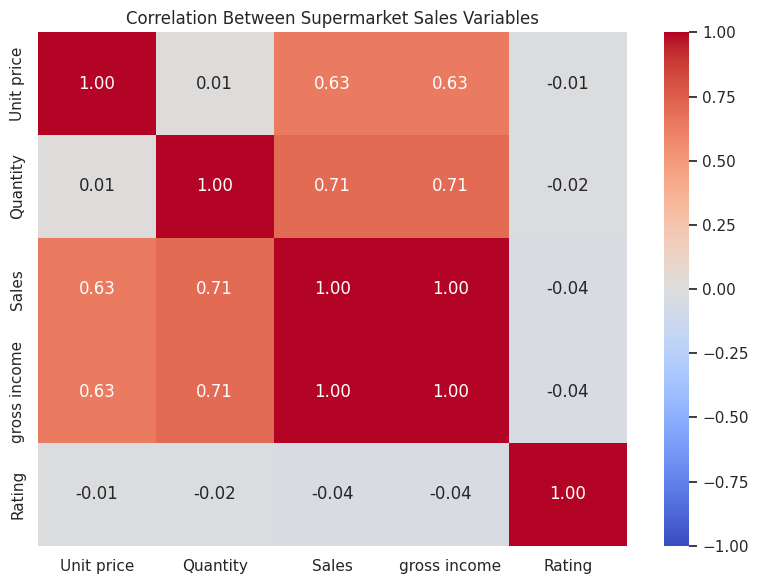

In [32]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Supermarket Sales Variables")
plt.tight_layout()
plt.show()

**Q4 — Grouping and time-series analysis [CO4, BL4]**

A — Sales by city and customer type:

In [25]:
city_analysis = df.groupby(
    ["City", "Customer type"]
).agg(
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Total_Quantity=("Quantity", "sum")
).round(2)

display(city_analysis)

print("City with highest sales:",
      df.groupby("City")["Sales"].sum().idxmax())

Total_Sales  Average_Sales  Total_Quantity
City      Customer type                                            
Mandalay  Member            59824.17         330.52            1002
          Normal            46373.50         307.11             818
Naypyitaw Member            66974.82         345.23            1073
          Normal            43593.89         325.33             758
Yangon    Member            62895.78         331.03            1106
          Normal            43304.59         288.70             753

City with highest sales: Naypyitaw


B — Daily sales trend:

,Sales
Date,
2019-01-01,4745.1810
2019-01-02,2444.5365
2019-01-03,2634.3660
2019-02-01,1945.5030
2019-02-02,4140.9480


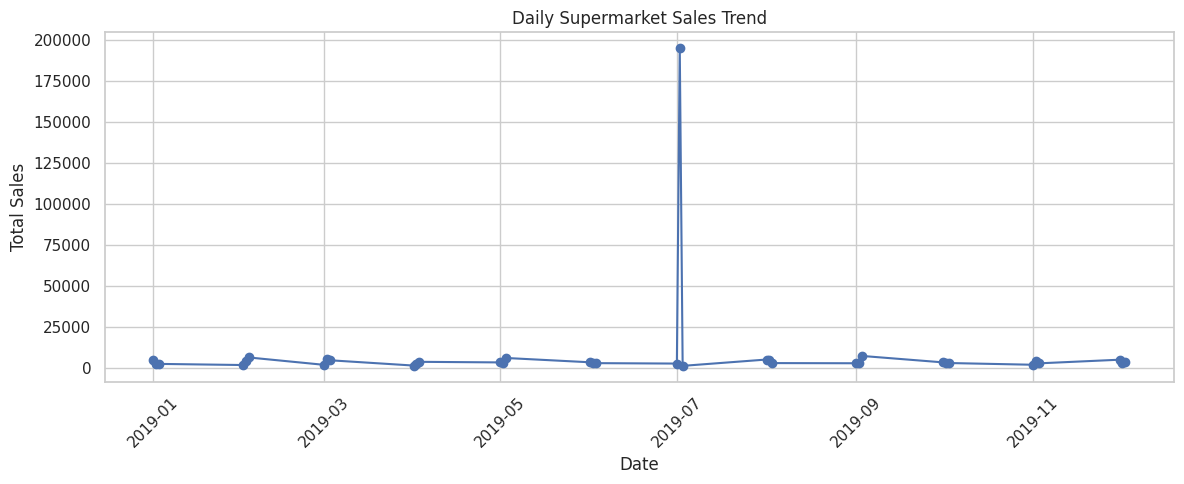

In [26]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

daily_sales = (
    df.dropna(subset=["Date"])
      .groupby(df["Date"].dt.date)["Sales"]
      .sum()
      .sort_index()
)

display(daily_sales.head())

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values, marker="o")
plt.title("Daily Supermarket Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Q5 — Data visualization using bar plots and heatmaps [CO5, BL5]**

A — Total sales by product line:

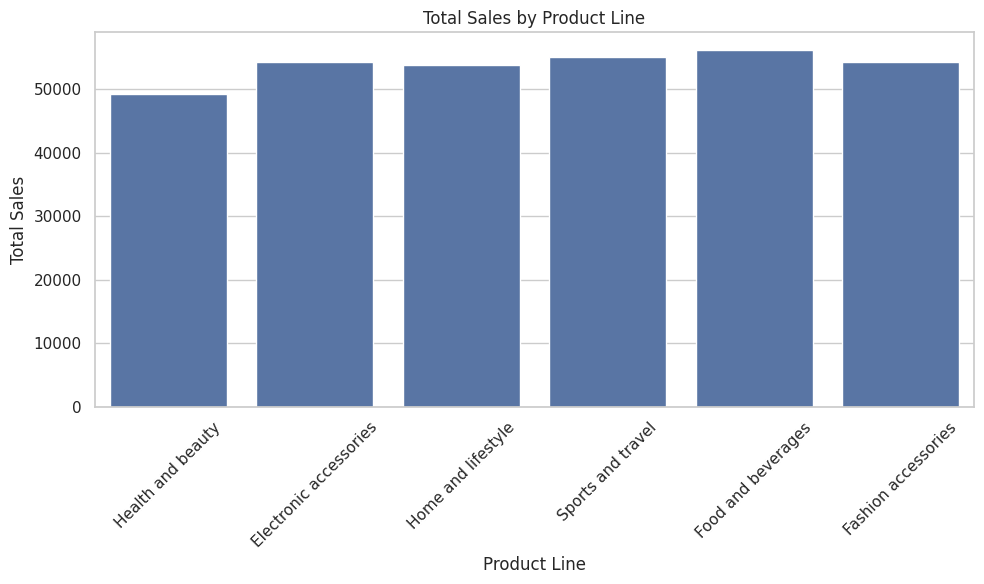

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Product line",
    y="Sales",
    estimator=sum,
    errorbar=None
)

plt.title("Total Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

B — Quantity sold by product line:

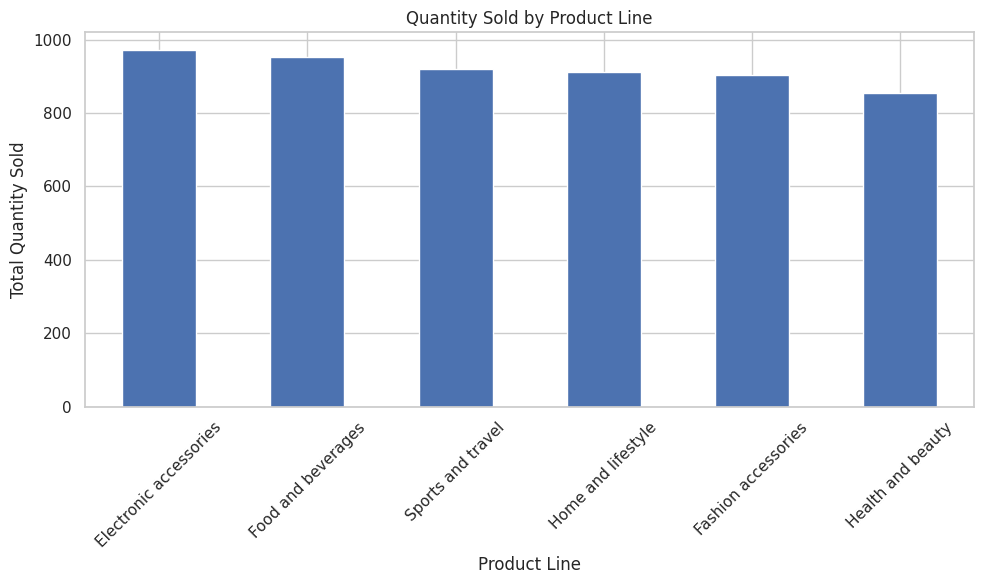

In [28]:
quantity_data = df.groupby(
    "Product line"
)["Quantity"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
quantity_data.plot(kind="bar")

plt.title("Quantity Sold by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C — Heatmap of sales by city and product line:

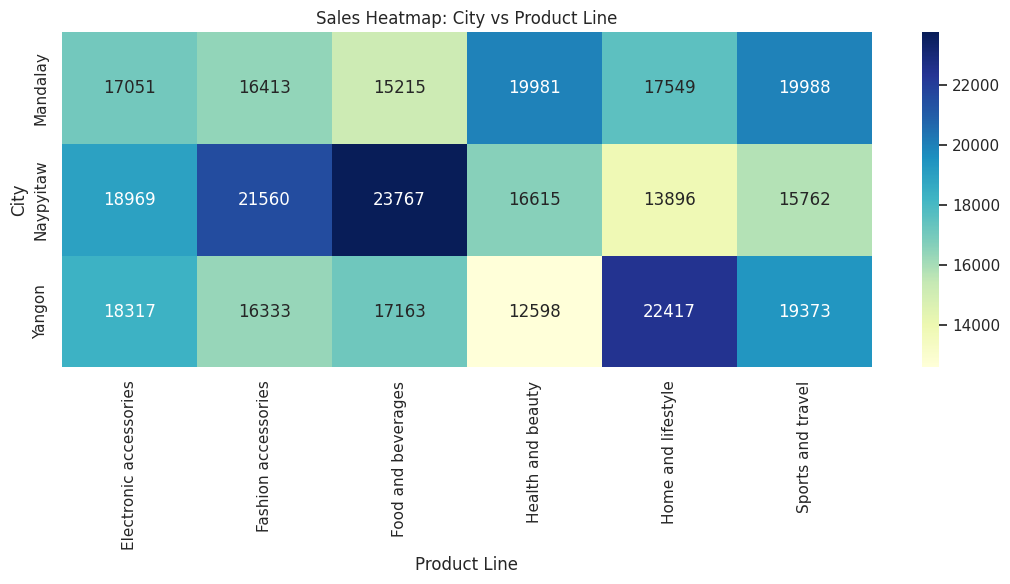

In [29]:
sales_pivot = df.pivot_table(
    index="City",
    columns="Product line",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(11, 6))
sns.heatmap(sales_pivot, annot=True, fmt=".0f", cmap="YlGnBu")

plt.title("Sales Heatmap: City vs Product Line")
plt.xlabel("Product Line")
plt.ylabel("City")
plt.tight_layout()
plt.show()

D — Payment method distribution:

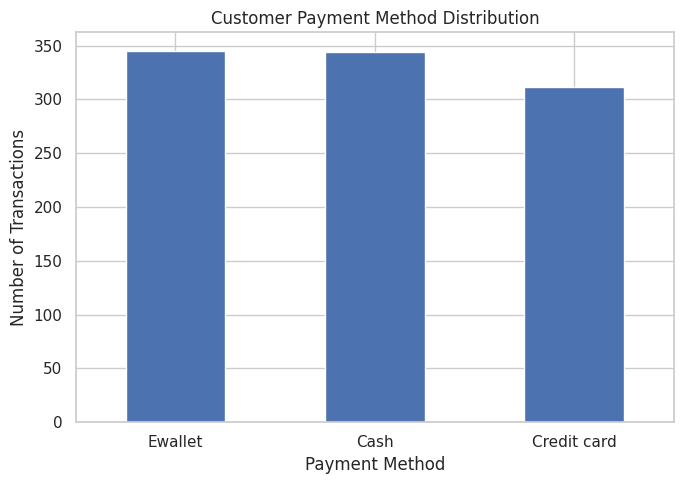

In [30]:
payment_counts = df["Payment"].value_counts()

plt.figure(figsize=(7, 5))
payment_counts.plot(kind="bar")

plt.title("Customer Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

E- Sales by product Line

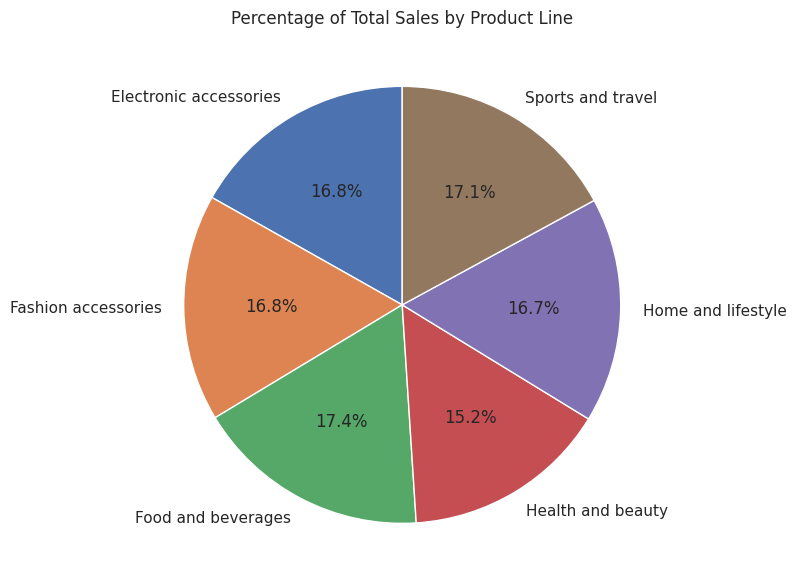

In [33]:
product_sales = df.groupby("Product line")["Sales"].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    product_sales,
    labels=product_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Total Sales by Product Line")
plt.tight_layout()
plt.show()